<a href="https://colab.research.google.com/github/LucMac0/Machine-Learning/blob/main/H%E1%BB%93i%20Quy/Hoang_Huu_Duc_2001240085_BTTL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Bai 1
#1.1
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)

# 1. Tao du lieu
dien_tich = 2 * np.random.rand(100, 1)
gia_nha = 4 + 3 * dien_tich + np.random.randn(100, 1)

# 2. Chia du lieu: X = dien tich, y = gia nha
dien_tich_train, dien_tich_test, gia_nha_train, gia_nha_test = train_test_split(
    dien_tich, gia_nha,
    test_size=0.2,
    random_state=42
)

# 3. Khoi tao mo hinh
model = LinearRegression()

# 4. Huan luyen mo hinh
model.fit(dien_tich_train, gia_nha_train)

# 5. Du doan gia nha
gia_nha_pred = model.predict(dien_tich_test)

# 6. Danh gia mo hinh
mse = mean_squared_error(gia_nha_test, gia_nha_pred)
r2 = r2_score(gia_nha_test, gia_nha_pred)

print(f"He so chan (Intercept): {model.intercept_[0]:.4f}")
print(f"He so goc (Slope): {model.coef_[0][0]:.4f}")
print(f"MSE: {mse:.4f}")
print(f"R^2 score: {r2:.4f}")

# 7. Ve bieu do
thu_tu = np.argsort(dien_tich_test[:, 0])

plt.scatter(
    dien_tich_test[:, 0],
    gia_nha_test[:, 0],
    color="blue",
    label="Du lieu thuc te"
)

plt.plot(
    dien_tich_test[thu_tu, 0],
    gia_nha_pred[thu_tu, 0],
    color="red",
    label="Du doan gia nha"
)

plt.title("Hoi quy tuyen tinh don gian")
plt.xlabel("Dien tich nha (m2)")
plt.ylabel("Gia nha (don vi gia lap)")
plt.legend()
plt.show()


In [ ]:
#1.2

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)

# 1. Tao 200 mau du lieu
n = 200
dien_tich = 2 * np.random.rand(n, 1)

# 2. Chia du lieu dien tich mot lan de so sanh cong bang
dien_tich_train, dien_tich_test = train_test_split(
    dien_tich,
    test_size=0.2,
    random_state=42
)

# 3. Thu nghiem voi ba muc do nhieu
muc_do_nhieu = [100, 500, 1500]

plt.figure(figsize=(10, 6))

for muc_nhieu in muc_do_nhieu:

    # Tao gia nha voi muc nhieu dang thu nghiem
    gia_nha = (
        4 + 3 * dien_tich
        + np.random.normal(0, muc_nhieu, (n, 1))
    )

    # Chia gia nha theo dung chi so cua tap dien tich
    gia_nha_train, gia_nha_test = train_test_split(
        gia_nha,
        test_size=0.2,
        random_state=42
    )

    # Huan luyen mo hinh
    model = LinearRegression()
    model.fit(dien_tich_train, gia_nha_train)

    # Du doan
    gia_nha_pred = model.predict(dien_tich_test)

    # Danh gia
    mse = mean_squared_error(gia_nha_test, gia_nha_pred)
    r2 = r2_score(gia_nha_test, gia_nha_pred)

    print(f"\nMUC NHIU: {muc_nhieu}")
    print(f"He so chan: {model.intercept_[0]:.4f}")
    print(f"He so goc: {model.coef_[0][0]:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"R2 Score: {r2:.4f}")

    # Ve du lieu va duong hoi quy
    plt.scatter(
        dien_tich_test[:, 0],
        gia_nha_test[:, 0],
        alpha=0.4,
        label=f"Du lieu - nhieu {muc_nhieu}"
    )

    thu_tu = np.argsort(dien_tich_test[:, 0])

    plt.plot(
        dien_tich_test[thu_tu, 0],
        gia_nha_pred[thu_tu, 0],
        label=f"Duong hoi quy - nhieu {muc_nhieu}"
    )

plt.title("Anh huong cua do nhieu den mo hinh hoi quy")
plt.xlabel("Dien tich nha (don vi gia lap)")
plt.ylabel("Gia nha (don vi gia lap)")
plt.legend()
plt.show()


In [ ]:
#1.3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)

# 1. Tao du lieu gia lap
n = 200

dien_tich = np.random.uniform(30, 150, n)
so_phong = np.random.randint(1, 6, n)
tuoi_nha = np.random.randint(0, 31, n)
khoang_cach = np.random.uniform(1, 20, n)

# 2. Tao gia nha dua tren nhieu yeu to
gia_nha = (
    100
    + 20 * dien_tich
    + 100 * so_phong
    - 10 * tuoi_nha
    - 15 * khoang_cach
    + np.random.normal(0, 200, n)
)

# 3. Gom cac bien dau vao thanh bang du lieu
X = pd.DataFrame({
    "Dien_tich": dien_tich,
    "So_phong": so_phong,
    "Tuoi_nha": tuoi_nha,
    "Khoang_cach": khoang_cach
})

y = gia_nha

print("5 dong du lieu dau tien:")
print(X.head())

# 4. Chia tap huan luyen va tap kiem tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 5. Khoi tao va huan luyen mo hinh
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Du doan gia nha
y_pred = model.predict(X_test)

# 7. Danh gia mo hinh
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nKET QUA MO HINH HOI QUY DA BIEN")
print(f"He so chan: {model.intercept_:.4f}")
print(f"MSE: {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

# 8. In he so cua tung bien
print("\nHE SO HOI QUY:")
for ten_bien, he_so in zip(X.columns, model.coef_):
    print(f"{ten_bien}: {he_so:.4f}")

# 9. Du doan mot can nha moi
nha_moi = pd.DataFrame({
    "Dien_tich": [80],
    "So_phong": [3],
    "Tuoi_nha": [5],
    "Khoang_cach": [4]
})

gia_du_doan = model.predict(nha_moi)

print("\nDU DOAN CAN NHA MOI")
print(f"Dien tich: 80")
print(f"So phong: 3")
print(f"Tuoi nha: 5")
print(f"Khoang cach: 4")
print(f"Gia nha du doan: {gia_du_doan[0]:.2f}")

# 10. So sanh gia tri thuc te va du doan
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    color="blue",
    alpha=0.7,
    label="Du doan"
)

gia_min = min(y_test.min(), y_pred.min())
gia_max = max(y_test.max(), y_pred.max())

plt.plot(
    [gia_min, gia_max],
    [gia_min, gia_max],
    color="red",
    linestyle="--",
    label="Du doan ly tuong"
)

plt.title("So sanh gia nha thuc te va du doan")
plt.xlabel("Gia nha thuc te")
plt.ylabel("Gia nha du doan")
plt.legend()
plt.show()

5 dong du lieu dau tien:
         BMI  Mac_benh
0  24.988963         0
1  38.817143         1
2  33.567855         1
3  30.367804         1
4  19.744447         0

So luong tung nhan:
Mac_benh
1    152
0    148
Name: count, dtype: int64

10 ket qua du doan dau tien:
   BMI_thuc_te  Nhan_thuc_te  Xac_suat_mac_benh  Nhan_du_doan
0       28.064             0              0.544             1
1       26.251             0              0.408             0
2       29.170             0              0.625             1
3       21.470             0              0.140             0
4       19.744             0              0.088             0
5       29.471             0              0.646             1
6       37.957             1              0.959             1
7       18.256             0              0.058             0
8       37.057             1              0.947             1
9       25.282             0              0.340             0

Accuracy: 0.8
Confusion Matrix:
[[22  8]
 [ 4 26]]

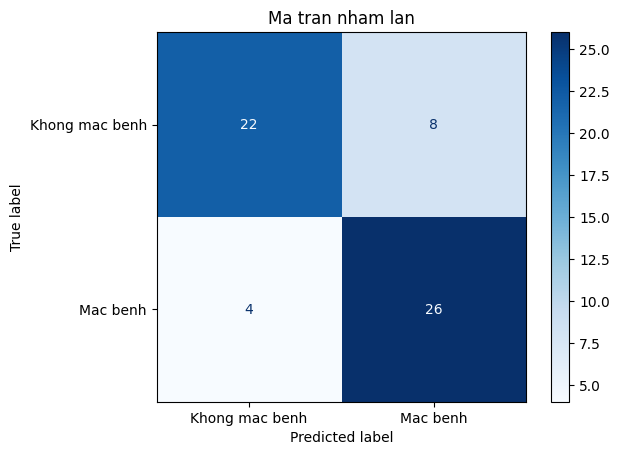

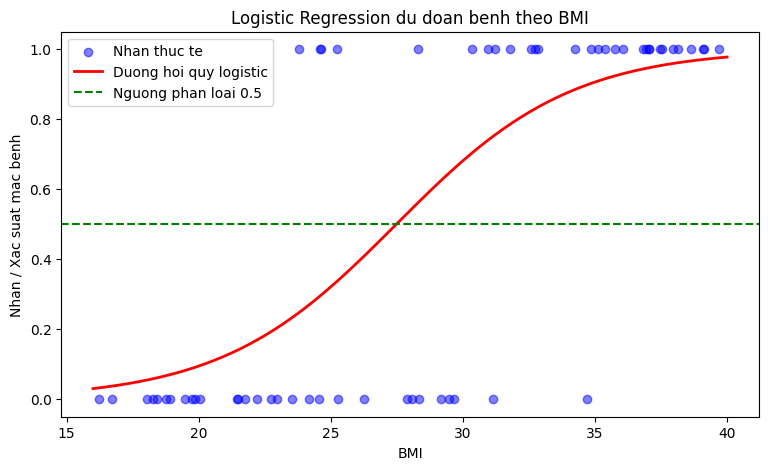

In [1]:
#Bai 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# ==========================================
# BUOC 1: TAO DU LIEU GIA LAP
# ==========================================

np.random.seed(42)

n = 300

# Tao BMI ngau nhien trong khoang 16 den 40
BMI = np.random.uniform(16, 40, n)

# BMI tang thi xac suat mac benh tang
xac_suat = 1 / (1 + np.exp(-(BMI - 28) / 3))

# Tao nhan 0 hoac 1 dua tren xac suat
Mac_benh = np.random.binomial(1, xac_suat)

df = pd.DataFrame({
    "BMI": BMI,
    "Mac_benh": Mac_benh
})

print("5 dong du lieu dau tien:")
print(df.head())

print("\nSo luong tung nhan:")
print(df["Mac_benh"].value_counts())

# ==========================================
# BUOC 2: CHIA DU LIEU
# ==========================================

X = df[["BMI"]]
y = df["Mac_benh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ==========================================
# BUOC 3: HUAN LUYEN MO HINH
# ==========================================

model = LogisticRegression()
model.fit(X_train, y_train)

# ==========================================
# BUOC 4: DU DOAN
# ==========================================

y_pred = model.predict(X_test)

# Xac suat mac benh (lop 1)
y_prob = model.predict_proba(X_test)[:, 1]

ket_qua = pd.DataFrame({
    "BMI_thuc_te": X_test["BMI"].values,
    "Nhan_thuc_te": y_test.values,
    "Xac_suat_mac_benh": y_prob,
    "Nhan_du_doan": y_pred
})

print("\n10 ket qua du doan dau tien:")
print(ket_qua.head(10).round(3))

# ==========================================
# BUOC 5: DANH GIA MO HINH
# ==========================================

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\nAccuracy:", round(accuracy, 4))
print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Khong mac benh", "Mac benh"]
)

disp.plot(cmap="Blues")
plt.title("Ma tran nham lan")
plt.show()

# ==========================================
# BUOC 6: VE DU LIEU VA DUONG LOGISTIC
# ==========================================

plt.figure(figsize=(9, 5))

plt.scatter(
    X_test["BMI"],
    y_test,
    color="blue",
    alpha=0.5,
    label="Nhan thuc te"
)

BMI_range = np.linspace(16, 40, 300).reshape(-1, 1)

xac_suat_du_doan = model.predict_proba(
    pd.DataFrame(BMI_range, columns=["BMI"])
)[:, 1]

plt.plot(
    BMI_range[:, 0],
    xac_suat_du_doan,
    color="red",
    linewidth=2,
    label="Duong hoi quy logistic"
)

plt.axhline(
    0.5,
    color="green",
    linestyle="--",
    label="Nguong phan loai 0.5"
)

plt.xlabel("BMI")
plt.ylabel("Nhan / Xac suat mac benh")
plt.title("Logistic Regression du doan benh theo BMI")
plt.legend()
plt.show()


In [ ]:


# BAI 3:

# BUOC 1: IMPORT THU VIEN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# BUOC 2: TAO BO DU LIEU
np.random.seed(42)

# Dien tich nha (m2)
dien_tich = np.random.randint(30, 201, 100)

# Gia nha (don vi gia lap: trieu dong)
gia_nha = 500 + 20 * dien_tich + np.random.normal(0, 200, 100)

# Tao DataFrame
df = pd.DataFrame({
    "Dien_tich": dien_tich,
    "Gia_nha": gia_nha
})

print("5 dong du lieu dau tien:")
print(df.head())

print("\nThong ke du lieu:")
print(df.describe())


# BUOC 3: CHUAN BI DU LIEU
X = df[["Dien_tich"]]
y = df["Gia_nha"]

# Chia du lieu: 80% huan luyen, 20% kiem tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nSo mau huan luyen:", len(X_train))
print("So mau kiem tra:", len(X_test))


# BUOC 4: XAY DUNG VA HUAN LUYEN MO HINH
model = LinearRegression()

model.fit(X_train, y_train)

print("\nHe so goc:", model.coef_[0])
print("He so chan:", model.intercept_)


# BUOC 5: DU DOAN VA DANH GIA MO HINH
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMSE:", round(mse, 2))
print("R2 Score:", round(r2, 4))

# So sanh gia tri thuc te va du doan
ket_qua = pd.DataFrame({
    "Dien_tich": X_test["Dien_tich"].values,
    "Gia_thuc_te": y_test.values,
    "Gia_du_doan": y_pred
})

print("\nKet qua du doan:")
print(ket_qua.head(10))


# BUOC 6: TRUC QUAN HOA MO HINH
plt.figure(figsize=(8, 5))

# Ve du lieu thuc te
plt.scatter(
    X_test["Dien_tich"],
    y_test,
    color="blue",
    label="Gia nha thuc te"
)

# Sap xep dien tich de ve duong hoi quy
X_line = pd.DataFrame({
    "Dien_tich": np.linspace(
        df["Dien_tich"].min(),
        df["Dien_tich"].max(),
        100
    )
})

y_line = model.predict(X_line)

plt.plot(
    X_line["Dien_tich"],
    y_line,
    color="red",
    label="Duong hoi quy"
)

plt.xlabel("Dien tich nha (m2)")
plt.ylabel("Gia nha (trieu dong)")
plt.title("Mo hinh hoi quy tuyen tinh du doan gia nha")
plt.legend()
plt.grid(True)
plt.show()


# BUOC 7: DU DOAN GIA NHA MOI
dien_tich_moi = pd.DataFrame({
    "Dien_tich": [100]
})

gia_du_doan = model.predict(dien_tich_moi)

print("\nDu doan gia nha co dien tich 100 m2:")
print(round(gia_du_doan[0], 2), "trieu dong")
